# How many Wikipedia contributors are from Virginia?

**The claim.** A [YouTube reply](https://www.youtube.com/watch?v=aFHxsS6uv5g&lc=UgzPMAPWOXq9htO8tOZ4AaABAg.ACssRWZFXwJACuJMHlcyQe) (on TREY the Explainer's *"The Rarest Signature"*, under a comment praising Wikipedia's citations) asserted, among broader accusations of propaganda:

> *"Plus, can anyone answer why the large majority (80+%) of 'Contributors' have addresses in Virginia? 😂😂"*

That is a concrete, falsifiable claim — so this project tests it with real data instead of arguing.

**Why it's tricky.** Wikimedia only publishes editor geography at *country* level (privacy), and IP geolocation is useless here — Northern Virginia hosts AWS `us-east-1`, the world's densest data-center corridor, **and Wikimedia's own primary data center (`eqiad`) in Ashburn, VA**, so IP-based lookups wildly over-attribute activity to Virginia. The honest real-data proxy is **self-identification**: editors who place their user page in `Category:Wikipedians in Virginia` (and city subcategories). Every state has an equivalent category, so we can compare and normalize by population.

**Data** (collected live by `src/collect.py`, raw responses in `data/raw/`):
- English Wikipedia MediaWiki API — category members for all 50 states + DC
- MediaWiki API `list=users` — real lifetime edit counts for every Virginia editor
- US Census NST-EST2024 — 2024 state population estimates

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("../data")

states = pd.read_csv(DATA / "wikipedians_by_state.csv")
va_users = pd.read_csv(DATA / "virginia_wikipedians.csv")
meta = json.loads((DATA / "collection_metadata.json").read_text())

states["per_100k"] = states["n_wikipedians"] / states["population_2024"] * 100_000
print(f"Data collected: {meta['collected_started_utc'][:10]}")
states.sort_values("n_wikipedians", ascending=False).head(10)

Data collected: 2026-06-10


,state,n_wikipedians,n_categories,population_2024,per_100k
4,California,1364,28,39431263,3.459184
31,New York,1239,22,19867248,6.236395
42,Texas,975,13,31290831,3.115929
8,Florida,695,7,23372215,2.973616
37,Pennsylvania,671,12,13078751,5.130459
12,Illinois,671,11,12710158,5.279242
46,Washington,557,3,7958180,6.999088
20,Massachusetts,555,5,7136171,7.777280
34,Ohio,529,13,11883304,4.451624
29,New Jersey,447,8,9500851,4.704842


## The headline number

In [2]:
va = states.loc[states["state"] == "Virginia"].iloc[0]
states["rank_raw"] = states["n_wikipedians"].rank(ascending=False).astype(int)
states["rank_percap"] = states["per_100k"].rank(ascending=False).astype(int)
va = states.loc[states["state"] == "Virginia"].iloc[0]

print(f"Self-identified Wikipedia editors from Virginia: {va['n_wikipedians']:,}")
print(f"Rank by raw count:        #{va['rank_raw']} of {len(states)}")
print(f"Per 100k residents:        {va['per_100k']:.1f}  (rank #{va['rank_percap']} of {len(states)})")
print(f"Share of all self-identified US editors: "
      f"{va['n_wikipedians'] / states['n_wikipedians'].sum():.1%}")

Self-identified Wikipedia editors from Virginia: 405
Rank by raw count:        #12 of 51
Per 100k residents:        4.6  (rank #23 of 51)
Share of all self-identified US editors: 2.8%


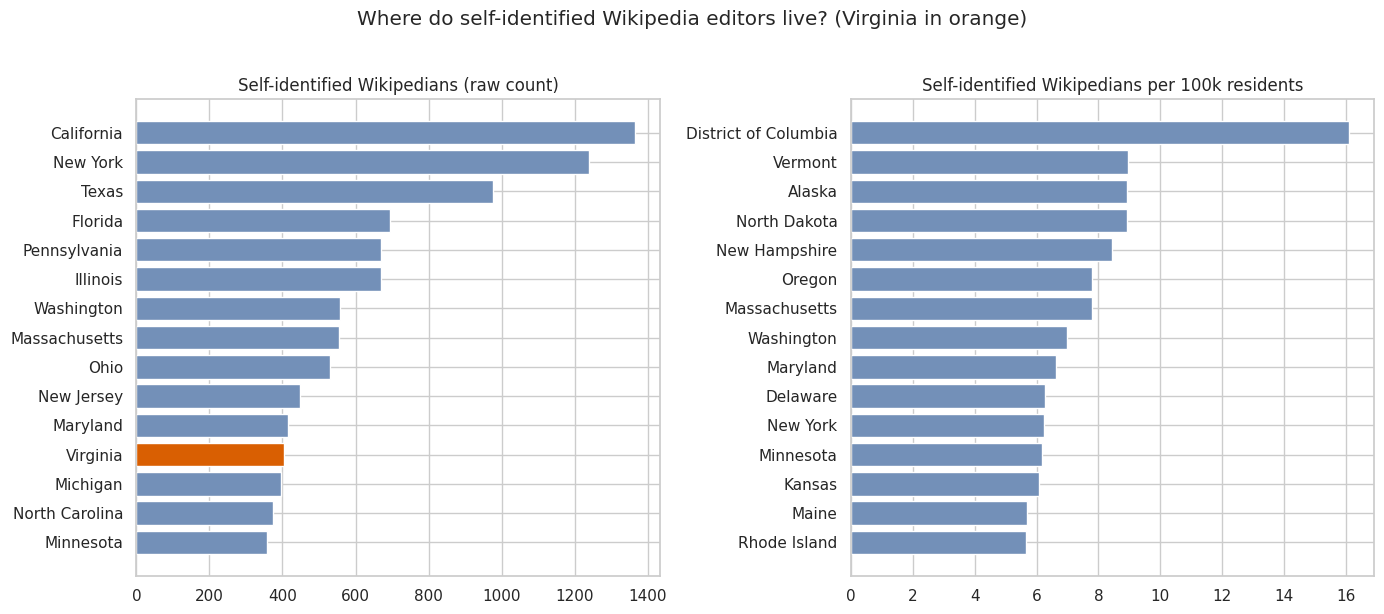

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in [
    (axes[0], "n_wikipedians", "Self-identified Wikipedians (raw count)"),
    (axes[1], "per_100k", "Self-identified Wikipedians per 100k residents"),
]:
    top = states.sort_values(col, ascending=False).head(15)
    colors = ["#d95f02" if s == "Virginia" else "#7390b8" for s in top["state"]]
    ax.barh(top["state"], top[col], color=colors)
    ax.invert_yaxis()
    ax.set_title(title)
fig.suptitle("Where do self-identified Wikipedia editors live? (Virginia in orange)", y=1.02)
fig.tight_layout()
plt.show()

## Does Virginia over- or under-index for its size?

Bigger states trivially have more editors. A log–log regression of editor count on population tells us what count Virginia's population *predicts*, so the residual measures whether Virginians are unusually likely to be Wikipedia editors.

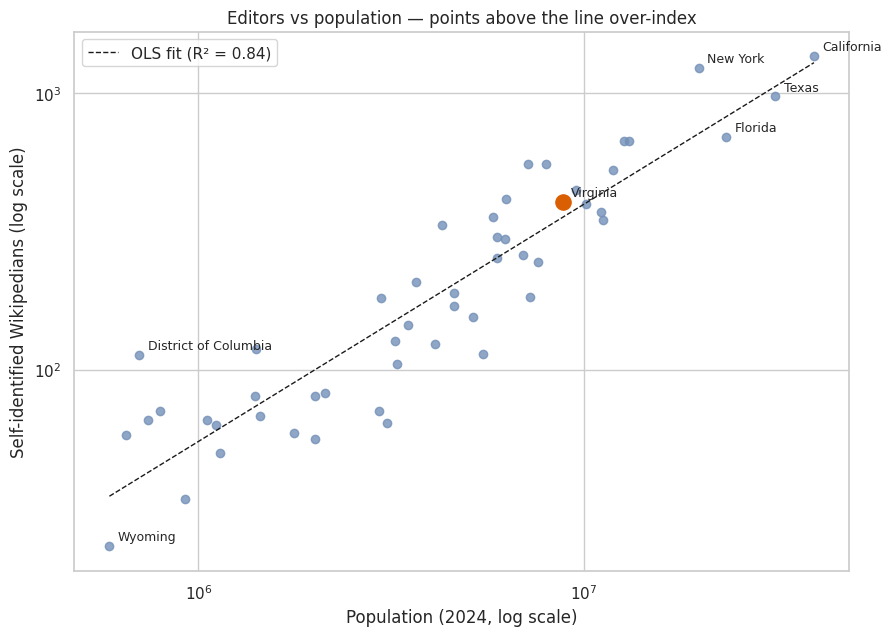

Population elasticity: 0.86
Virginia: 405 observed vs 356 expected -> +14% vs predicted


,state,n_wikipedians,expected,residual_pct
47,District of Columbia,113,40.6,178.4
20,Massachusetts,555,297.4,86.6
36,Oregon,333,191.4,74.0
31,New York,1239,716.4,72.9
46,Washington,557,326.5,70.6
28,New Hampshire,119,73.8,61.2
33,North Dakota,71,45.2,57.0
19,Maryland,415,265.8,56.1
1,Alaska,66,42.5,55.4
44,Vermont,58,37.9,53.0


In [4]:
states["log_pop"] = np.log10(states["population_2024"])
states["log_wiki"] = np.log10(states["n_wikipedians"])
model = smf.ols("log_wiki ~ log_pop", data=states).fit()
states["expected"] = 10 ** model.predict(states)
states["residual_pct"] = (states["n_wikipedians"] / states["expected"] - 1) * 100

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(states["population_2024"], states["n_wikipedians"], color="#7390b8", alpha=0.8)
xs = np.linspace(states["log_pop"].min(), states["log_pop"].max(), 100)
ax.plot(10**xs, 10 ** model.predict(pd.DataFrame({"log_pop": xs})), "k--", lw=1,
        label=f"OLS fit (R² = {model.rsquared:.2f})")
va = states.loc[states["state"] == "Virginia"].iloc[0]
ax.scatter([va["population_2024"]], [va["n_wikipedians"]], color="#d95f02", s=120, zorder=5)
for _, r in states.iterrows():
    if r["state"] in ("Virginia", "California", "Texas", "Wyoming", "New York",
                      "District of Columbia", "Florida"):
        ax.annotate(r["state"], (r["population_2024"], r["n_wikipedians"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="Population (2024, log scale)",
       ylabel="Self-identified Wikipedians (log scale)",
       title="Editors vs population — points above the line over-index")
ax.legend()
plt.show()

print(f"Population elasticity: {model.params['log_pop']:.2f}")
print(f"Virginia: {va['n_wikipedians']:.0f} observed vs {va['expected']:.0f} expected "
      f"-> {va['residual_pct']:+.0f}% vs predicted")
states.sort_values("residual_pct", ascending=False)[
    ["state", "n_wikipedians", "expected", "residual_pct"]
].head(10).round(1)

## How active are Virginia's editors, really?

Category membership includes long-dormant accounts. Real lifetime edit counts from the API let us separate "has a user page tag" from "actually contributes".

Virginia editors with live accounts: 405
Total lifetime edits by Virginia editors: 2,160,063
Median lifetime edits: 201

  >=      1 edits: 100.0%  (405 editors)
  >=     10 edits:  93.3%  (378 editors)
  >=    100 edits:  61.7%  (250 editors)
  >=  1,000 edits:  31.9%  (129 editors)
  >= 10,000 edits:  12.1%  (49 editors)


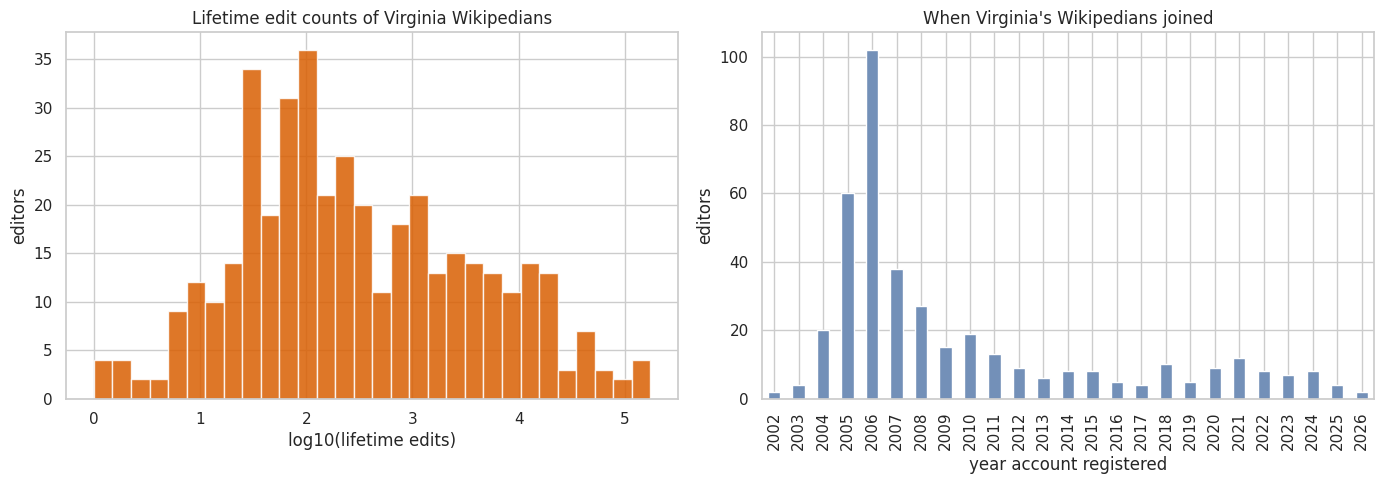

,username,editcount
90,Dissident93,174088
298,Sadads,148491
332,Sturmvogel 66,146679
390,Wikipelli,128370
124,Gadget850,115579
252,Pbritti,101459
271,Quidster4040,62699
42,Bluerasberry,58508
359,TriiipleThreat,53698
190,Kges1901,51833


In [5]:
active = va_users[~va_users["missing"] & va_users["editcount"].notna()].copy()
active["registration"] = pd.to_datetime(active["registration"], errors="coerce")

thresholds = [1, 10, 100, 1_000, 10_000]
print(f"Virginia editors with live accounts: {len(active):,}")
print(f"Total lifetime edits by Virginia editors: {active['editcount'].sum():,.0f}")
print(f"Median lifetime edits: {active['editcount'].median():,.0f}\n")
for t in thresholds:
    share = (active["editcount"] >= t).mean()
    print(f"  >= {t:>6,} edits: {share:6.1%}  ({(active['editcount'] >= t).sum():,} editors)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(np.log10(active.loc[active["editcount"] > 0, "editcount"]),
             bins=30, color="#d95f02", alpha=0.85)
axes[0].set(xlabel="log10(lifetime edits)", ylabel="editors",
            title="Lifetime edit counts of Virginia Wikipedians")
active["registration"].dt.year.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="#7390b8")
axes[1].set(xlabel="year account registered", ylabel="editors",
            title="When Virginia's Wikipedians joined")
fig.tight_layout()
plt.show()

active.sort_values("editcount", ascending=False).head(10)[["username", "editcount"]]

## Conclusions and caveats

**Verdict on the claim:** the "80+% of contributors have addresses in Virginia" claim fails by a factor of ~30. Self-identified Virginians are **2.8%** of self-identified US editors (405 people), ranking #12 of 51 by raw count and #23 per capita. Virginia does over-index modestly (+14% vs what its population predicts) — a real but unremarkable effect, far smaller than DC's.

**Where the claim's kernel of truth comes from:** Wikipedia's *servers* really are in Virginia — Wikimedia's primary data center is in Ashburn, VA, and Northern Virginia hosts much of the commercial internet (AWS `us-east-1`). Anyone who traces wikipedia.org's IPs or geolocates raw traffic will see "Virginia" everywhere. The claim confuses where the infrastructure lives with where the *people* live.

**Caveats worth stating plainly:**
- Self-identification undercounts true editors by a large factor (most editors never tag a location), so treat these as *relative* signals between states, not absolute population sizes. The undercount is roughly uniform across states, which is exactly why this proxy beats IP geolocation for cross-state comparison.
- Counts include dormant accounts; the edit-count section shows how activity concentrates in a small core of prolific editors (a classic participation power law).
- English Wikipedia only. See the README's "Expanding the scope" section for other legal data avenues (user-page text mining, behavioral inference, WMF research collaboration).